In [3]:
import numpy as np

from scipy.signal import find_peaks, savgol_filter
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect
from itertools import product


output_dir = '/home/cparis/00PhD/DS_PCBreview/'



theta_step = 2
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())


stim = np.arange(0,360,theta_step)

example = 201
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
example_quad_pars = data_dict['all_quad_pars'][example,bio_idx]
example_quad_tc = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in example_quad_pars])

np.random.seed(0)
exp_num, cell_idx = zip(*data_dict['exp_quad_list'])
exp_num = np.array(exp_num)

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


In [51]:
# main_dir = '/home/cparis/00PhD/'
# raw_data_dir = main_dir+'Raw Data/'

# experiment_number =1
# experiment_name = f'Exp{experiment_number}'

# with open(raw_data_dir+experiment_name+'.pkl', 'rb') as rick:
#     experimental_data = pickle.load(rick)
# print(experimental_data['dir_assigned_manually'].shape)    




(17, 1)


In [4]:
print(np.array(cell_idx))

[[ 5  3  0  9]
 [ 5  3  0 10]
 [ 5  3  0 11]
 ...
 [ 2  1  0  5]
 [ 3  1  0  4]
 [ 3  1  0  5]]


In [5]:
from concurrent.futures import ProcessPoolExecutor
def process_width(tc_width):
    return [ssiMod.MC_SSI(tc_quad) for tc_quad in tc_width]

In [ ]:
big_pop_dict = {}

nsample = 200

oct_popsize, key_prefix = 8, 'octu'
hxdc_popsize, key_prefix = 16, 'hxdc'

nsample_exps = np.sort(np.random.choice(np.arange(1,7), nsample, replace = True))
e=1
octuplet_idxs = np.array([np.random.choice(idx_list, oct_popsize//4) \
                                    for idx_list in [np.where(exp_num==e)[0] \
                                    for e in nsample_exps]])
octuplet_pars = data_dict['all_quad_pars'][octuplet_idxs].transpose(0,2,1,3,4).reshape(nsample,-1,oct_popsize,5)
octuplet_tcs = np.array([np.array([np.array([ssiMod.FTVM(stim, *pars) for pars in oct_pars]) \
                                       for oct_pars in width]) for width in octuplet_pars])
octuplet_fwhm = np.array([np.array([np.array([ssiMod.FWHM(pars)[1] for pars in oct_pars]) \
                                       for oct_pars in width]) for width in octuplet_pars])

big_pop_dict['octuplet_idxs'] = octuplet_idxs
big_pop_dict['all_multipliers'] = data_dict['all_multipliers']

big_pop_dict['octuplet_pars'] = octuplet_pars
big_pop_dict['octuplet_tcs'] = octuplet_tcs
big_pop_dict['octuplet_fwhm'] = octuplet_fwhm

# octuplet_ssis = np.array([np.array([ssiMod.MC_SSI(oct_tc) \
#                                               for oct_tc in tqdm(width)]) for width in tqdm(octuplet_tcs)])
# big_pop_dict['octuplet_ssis'] = octuplet_ssis
# with open(f'./Data folder/Big_pop/big_pop_ssi_results.pkl', 'wb') as rick:
#     pickle.dump(big_pop_dict, rick, protocol = 4)

octuplet_ssis = []

for i, width in enumerate(tqdm(octuplet_tcs)):
    width_ssis = []

#     for oct_tc in tqdm(width, leave=False):
#         ssi = ssiMod.MC_SSI(oct_tc)
#         width_ssis.append(ssi)

#         # Save progressively after each SSI computation
#         if 'octuplet_ssis' not in big_pop_dict:
#             big_pop_dict['octuplet_ssis'] = []

#         big_pop_dict['octuplet_ssis'].append(ssi)

#         with open('./Data folder/Big_pop/big_pop_ssi_results.pkl', 'wb') as rick:
#             pickle.dump(big_pop_dict, rick, protocol=4)
    for oct_tc in tqdm(width, leave=False):
        ssi = ssiMod.MC_SSI(oct_tc)
        width_ssis.append(ssi)

    # Save once per width
    if 'octuplet_ssis' not in big_pop_dict:
        big_pop_dict['octuplet_ssis'] = []

    big_pop_dict['octuplet_ssis'].append(width_ssis.copy())

    with open('./Data folder/Big_pop/big_pop_ssi_results.pkl', 'wb') as rick:
        pickle.dump(big_pop_dict, rick, protocol=4)


    octuplet_ssis.append(np.array(width_ssis))

octuplet_ssis = np.array(octuplet_ssis)
big_pop_dict['octuplet_ssis_array'] = octuplet_ssis    


# hxdc_popsize = 16
# hxdcplet_idxs = np.array([np.random.choice(idx_list, hxdc_popsize//4) \
#                                     for idx_list in [np.where(exp_num==e)[0] \
#                                     for e in nsample_exps]])
# hxdcplet_pars = data_dict['all_quad_pars'][hxdcplet_idxs].transpose(0,2,1,3,4).reshape(nsample,-1,hxdc_popsize,5)
# hxdcplet_tcs = np.array([np.array([np.array([ssiMod.FTVM(stim, *pars) for pars in hxdc_pars]) \
#                                        for hxdc_pars in width]) for width in hxdcplet_pars])
# hxdcplet_fwhm = np.array([np.array([np.array([ssiMod.FWHM(pars)[1] for pars in hxdc_pars]) \
#                                        for hxdc_pars in width]) for width in hxdcplet_pars])
# hxdcplet_ssis = np.array([np.array([ssiMod.MC_SSI(hxdc_tc) \
#                                               for hxdc_tc in tqdm(width)]) for width in tqdm(hxdcplet_tcs[:2])])

# # with ProcessPoolExecutor(max_workers=2) as executor:
# #     all_ssis = np.array(list(tqdm(executor.map(process_width, hxdcplet_tcs[:2]),total=len(hxdcplet_tcs[:2]))))

# big_pop_dict['all_multipliers'] = data_dict['all_multipliers']
# big_pop_dict['hxdcplet_idxs'] = hxdcplet_idxs
# big_pop_dict['hxdcplet_pars'] = hxdcplet_pars
# big_pop_dict['hxdcplet_tcs'] = hxdcplet_tcs
# big_pop_dict['hxdcplet_fwhm'] = hxdcplet_fwhm
# big_pop_dict['hxdcplet_ssis'] = hxdcplet_ssis

# with open('./Data folder/Big_pop/big_pop_ssi_results.pkl', 'wb') as rick:
#     pickle.dump(big_pop_dict, rick, protocol = 4)

# plt.plot(stim, )

# print(np.array([np.random.choice(idx_list, 2) for idx_list in [np.where(exp_num==e)[0] \
#                                     for e in nsample_exps]]))
# print(data_dict['original_cell_idx_quads'][exp_num==e])
# print(np.random.choice(data_dict['original_cell_idx_quads'][exp_num==e], 2))

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

...

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

dict_keys(['octuplet_idxs', 'octuplet_pars', 'octuplet_tcs', 'octuplet_fwhm', 'octuplet_ssis', 'hxdcplet_idxs', 'all_multipliers', 'hxdcplet_pars', 'hxdcplet_tcs', 'hxdcplet_fwhm', 'hxdcplet_ssis'])
(16, 180)
(16, 180)


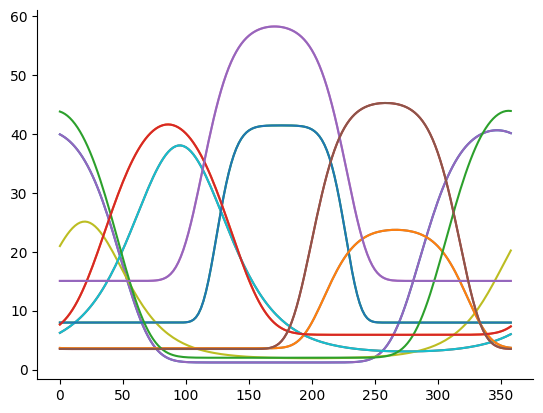

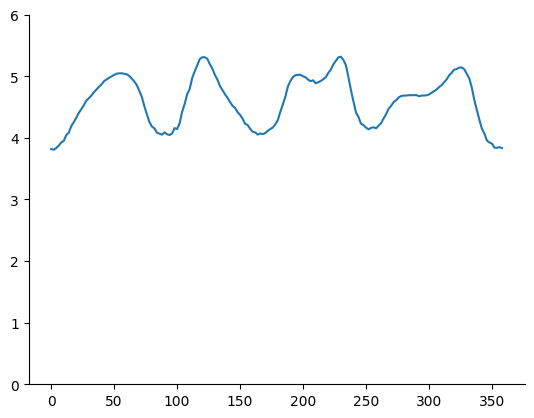

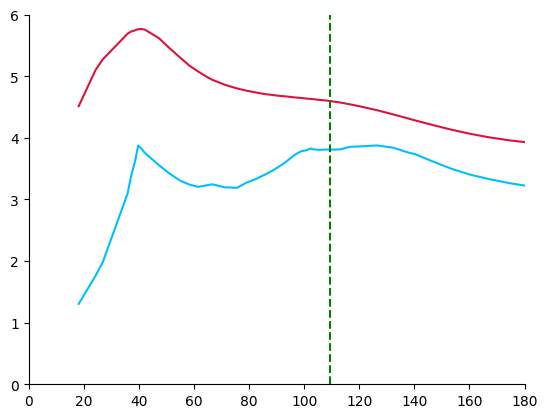

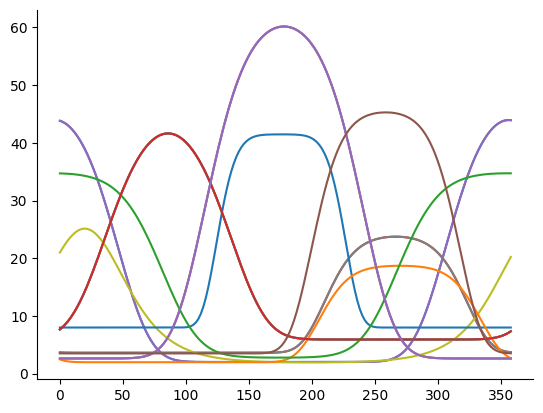

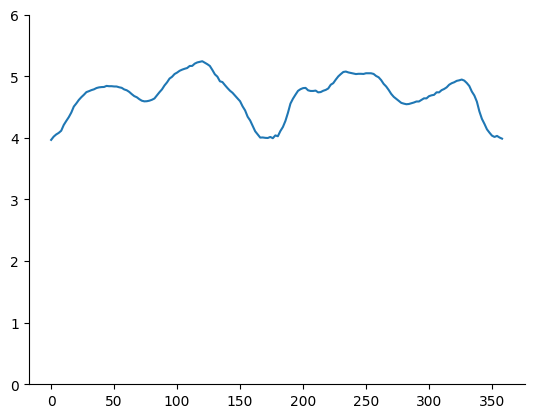

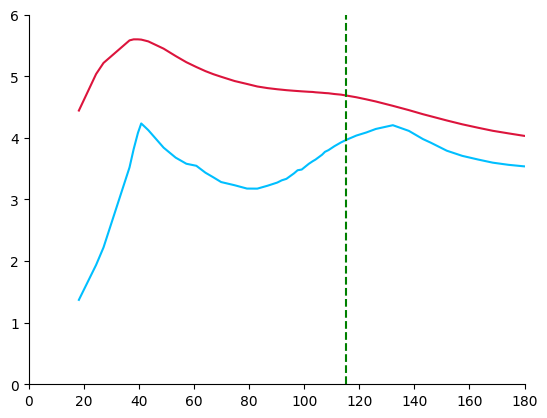

In [114]:
with open('./Data folder/Big_pop/big_pop_ssi_results.pkl', 'rb') as rick:
    big_pop_dict = pickle.load(rick)
print(data_dict.keys())

for i, el in enumerate(big_pop_dict['hxdcplet_tcs'][:2,bio_idx]):
    print(el.shape)
    plt.figure()
    plt.plot(stim, el.T)
    plt.figure()
    plt.plot(stim, big_pop_dict['hxdcplet_ssis'][i,bio_idx])
    plt.ylim(0,6)
    plt.figure()
    plt.plot(big_pop_dict['hxdcplet_fwhm'][i].mean(axis=1), big_pop_dict['hxdcplet_ssis'][i].min(axis=1),\
            color = 'deepskyblue')
    plt.plot(big_pop_dict['hxdcplet_fwhm'][i].mean(axis=1), big_pop_dict['hxdcplet_ssis'][i].mean(axis=1),\
            color = 'crimson')   
    plt.axvline(big_pop_dict['hxdcplet_fwhm'][i,bio_idx].mean(), color = 'g', ls='--')
    plt.ylim(0,6)
    plt.xlim(0,180)

In [92]:
np.random.seed(0)
# print(data_dict['original_cell_idx_quads'])
exp_num, cell_idx = zip(*data_dict['exp_quad_list'])
exp_num = np.array(exp_num)
cell_idx= np.array(cell_idx)

experiment_number = 5

pop_mult = 5

pop_cell_idx = np.random.choice(np.count_nonzero(exp_num==experiment_number),pop_mult, replace = False)
print(pop_cell_idx)

oct_tcs = data_dict['all_quad_tc'][exp_num==experiment_number][pop_cell_idx].transpose(1,0,2,3).reshape(len(data_dict['all_multipliers']),pop_mult*4,-1)

print(oct_tcs.shape)
oct_ssis = np.array([ssiMod.MC_SSI(oct_tc) for oct_tc in tqdm(oct_tcs)])

[110 112 143   7  44]
(56, 20, 180)


  0%|          | 0/56 [00:00<?, ?it/s]

In [95]:
print(data_dict['all_quad_fwhm'][exp_num==experiment_number][pop_cell_idx].shape)
oct_widths = data_dict['all_quad_fwhm'][exp_num==experiment_number][pop_cell_idx].transpose(1,0,2).reshape(len(data_dict['all_multipliers']),-1)
print(oct_widths.shape)

(5, 56, 4)
(56, 20)


(0.0, 7.0)

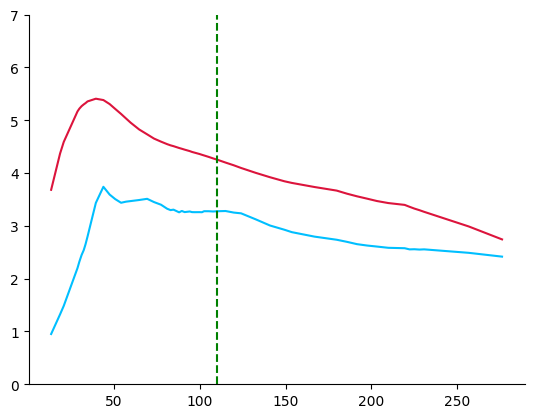

In [96]:
plt.plot(oct_widths.mean(axis=1), oct_ssis.min(axis=1), color = 'deepskyblue')
plt.plot(oct_widths.mean(axis=1), oct_ssis.mean(axis=1), color = 'crimson')
plt.axvline(oct_widths.mean(axis=1)[bio_idx], color ='green', linestyle='dashed')
plt.ylim(0,7)